In [2]:
from google.colab import drive

drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)
import sys
sys.path.append('/content/drive/MyDrive/fed_project')

from common_modules import *
from preprocessing import preprocess_data
from federated_methods import*



Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive



FEDAVG----Number of clients: 2
Round 1, Accuracy: 0.8084 | Precision: 0.7004 | Sensitivity: 0.8491 | F1: 0.7676
Round 2, Accuracy: 0.8963 | Precision: 0.8148 | Sensitivity: 0.9340 | F1: 0.8703
Round 3, Accuracy: 0.9192 | Precision: 0.8547 | Sensitivity: 0.9434 | F1: 0.8969
Round 4, Accuracy: 0.9297 | Precision: 0.8739 | Sensitivity: 0.9481 | F1: 0.9095
Round 5, Accuracy: 0.9350 | Precision: 0.8855 | Sensitivity: 0.9481 | F1: 0.9157
Round 6, Accuracy: 0.9420 | Precision: 0.9013 | Sensitivity: 0.9481 | F1: 0.9241
Round 7, Accuracy: 0.9438 | Precision: 0.9018 | Sensitivity: 0.9528 | F1: 0.9266
Round 8, Accuracy: 0.9490 | Precision: 0.9103 | Sensitivity: 0.9575 | F1: 0.9333
Round 9, Accuracy: 0.9508 | Precision: 0.9144 | Sensitivity: 0.9575 | F1: 0.9355
Round 10, Accuracy: 0.9525 | Precision: 0.9148 | Sensitivity: 0.9623 | F1: 0.9379

FEDAVG----Number of clients: 3
Round 1, Accuracy: 0.5905 | Precision: 0.4685 | Sensitivity: 0.7358 | F1: 0.5725
Round 2, Accuracy: 0.8664 | Precision: 0.769

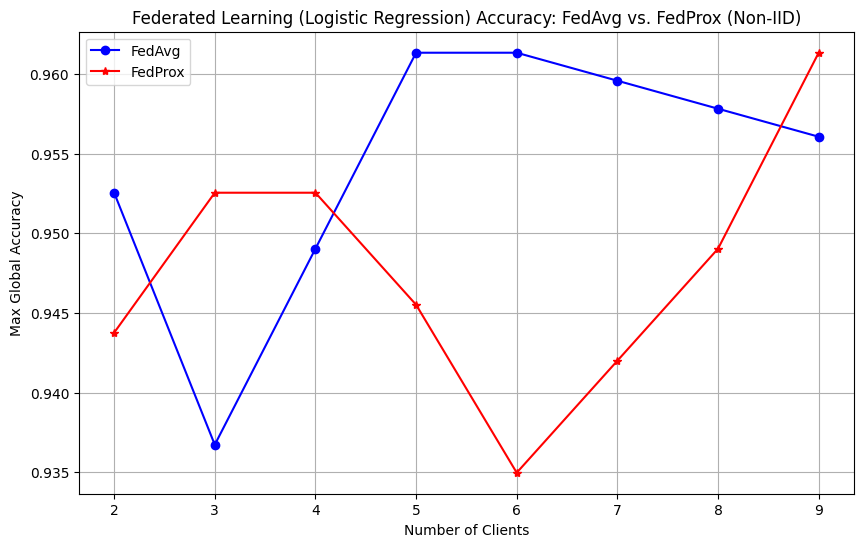

In [4]:

# Define the Logistic Regression model
class LogisticRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        out = self.linear(x)
        return out


# Load and preprocess the dataset



# Robust Non-IID Splitting using Dirichlet Distribution
def split_data_non_iid(X, y, num_clients, alpha=0.5):
    unique_classes = np.unique(y)
    num_classes = len(unique_classes)

    client_indices = [[] for _ in range(num_clients)]

    # Distribute samples of each class dynamically
    for cls in unique_classes:
        cls_indices = np.where(y == cls)[0]
        np.random.shuffle(cls_indices)

        # Use Dirichlet distribution to obtain non-iid proportions for each client
        proportions = np.random.dirichlet([alpha] * num_clients)
        proportions = (proportions * len(cls_indices)).astype(int)

        # Correct any rounding differences to ensure all samples are assigned
        difference = len(cls_indices) - sum(proportions)
        for d in range(difference):
            proportions[d % num_clients] += 1

        current_idx = 0
        for client_id, count in enumerate(proportions):
            client_indices[client_id].extend(cls_indices[current_idx:current_idx + count])
            current_idx += count

    client_data = []
    for indices in client_indices:
        np.random.shuffle(indices)
        client_data.append((X[indices], y[indices]))

    return client_data

# using federated methods after importing

def run_logistic_federated_simulation(algorithm_name, mu=0.01):
    num_rounds = 10
    input_dim = 30
    output_dim = 2

    # Preprocessing the dataset
    X, y = preprocess_data(DATA_PATH)

    cl, acc = [], []
    for i in range(2, 10):
        client_data = split_data_non_iid(X, y, i, alpha=0.5)
        print(f"\n{algorithm_name.upper()}----Number of clients: {i}")
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = LogisticRegression(input_dim, output_dim)

        for round in range(num_rounds):
            client_models = []
            global_model_copy = copy.deepcopy(model)

            for client_data_batch in federated_data:
                # Avoid training if dataset is empty
                if len(client_data_batch['X']) == 0:
                    continue

                local_model = LogisticRegression(input_dim, output_dim)
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.CrossEntropyLoss()

                # Performing local training
                for epoch in range(10):
                    optimizer.zero_grad()
                    outputs = local_model(client_data_batch['X'])
                    loss = criterion(outputs, client_data_batch['y'])

                    if algorithm_name.lower() == 'fedprox':
                        # Calculating the L2 proximal term for FedProx
                        proximal_term = 0.0
                        for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                            proximal_term += torch.sum((local_param - global_param.detach()) ** 2)
                        loss = loss + (mu / 2) * proximal_term

                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Aggregating client models
            if len(client_models) > 0:
                if algorithm_name.lower() == 'fedprox':
                    averaged_state_dict = fedprox(model, client_models)
                else:
                    averaged_state_dict = federated_average(model, client_models)
                model.load_state_dict(averaged_state_dict)

            # Calculating global accuracy and extra metrics
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                _, predicted = torch.max(outputs, dim=1)

                y_true = np.array(y)
                y_pred = predicted.numpy()

                accuracy = (predicted == torch.tensor(y, dtype=torch.long)).float().mean().item()
                precision = precision_score(y_true, y_pred, average='binary', zero_division=0)
                recall = recall_score(y_true, y_pred, average='binary', zero_division=0)
                f1 = f1_score(y_true, y_pred, average='binary', zero_division=0)

                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | Sensitivity: {recall:.4f} | F1: {f1:.4f}')

        acc.append(max_acc)
    return cl, acc

def main():
    # Running both simulations(fed avg and fed prox simultaneously)
    cl_avg, acc_avg = run_logistic_federated_simulation('fedavg')
    cl_prox, acc_prox = run_logistic_federated_simulation('fedprox', mu=0.01)

    # Plotting unified results
    plt.figure(figsize=(10, 6))
    plt.plot(cl_avg, acc_avg, marker='o', label='FedAvg', color='blue')
    plt.plot(cl_prox, acc_prox, marker='*', label='FedProx', color='red')
    plt.xlabel('Number of Clients')
    plt.ylabel('Max Global Accuracy')
    plt.title('Federated Learning (Logistic Regression) Accuracy: FedAvg vs. FedProx (Non-IID)')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    main()